# 01 – SGI2023 glaciers in the initial study area

How many SGI2023 glaciers intersect the Mischabel–Weisshorn massif, and how large are they?

This exploration uses the **initial** area (7.6–7.95° E, 46.0–46.15° N). The final study extent, enlarged to include whole glaciers, is defined in `src/config.py`.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
from shapely.geometry import box

# Project root: paths are relative to it (the notebook runs from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from relief import hillshade

In [2]:
sgi = gpd.read_file(ROOT / "data/raw/sgi2023/SGI_2023_glaciers.shp")
print("CRS:", sgi.crs)

CRS: EPSG:2056


In [3]:
# Area in WGS84 -> reprojected to LV95
area = gpd.GeoDataFrame(geometry=[box(7.6, 46.0, 7.95, 46.15)], crs=4326).to_crs(2056)

intersecting = sgi[sgi.intersects(area.geometry[0])]
inside = sgi[sgi.within(area.geometry[0])]
print("Intersecting:", len(intersecting), "| Entirely inside:", len(inside))

Intersecting: 113 | Entirely inside: 97


In [4]:
# Area recomputed from the geometry, kept next to the official SGI area_km2
intersecting = intersecting.assign(area_geom_km2=intersecting.area / 1e6)
print(intersecting["area_geom_km2"].describe())
print("< 0.5 km²:", (intersecting["area_geom_km2"] < 0.5).sum())

count    113.000000
mean       1.380334
std        2.870400
min        0.011373
25%        0.056119
50%        0.238809
75%        1.153205
max       13.695879
Name: area_geom_km2, dtype: float64
< 0.5 km²: 70


In [5]:
print(intersecting.columns.tolist())

['gid', 'pk_glacier', 'sgi-id', 'name', 'rl_3', 'rl_2', 'rl_1', 'rl_0', 'i_code', 'year_acq', 'year_rel', 'area_km2', 'length_km', 'masl_min', 'masl_med', 'masl_mean', 'masl_max', 'slope_deg', 'aspect_deg', 'geometry', 'area_geom_km2']


## Map of the glaciers in the area

Background: hillshade computed from swissALTI3D, resampled to 20 m for display.

In [6]:
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.merge import merge

# Mosaic of the swissALTI3D tiles at 20 m (enough for a background map).
# Areas without a tile get NaN so they do not show up as flat grey.
tiles = [rasterio.open(f) for f in sorted((ROOT / "data/raw/swissalti3d").glob("*.tif"))]
dem, transform = merge(tiles, res=20, nodata=np.nan)
for t in tiles:
    t.close()
dem = dem[0]

shade = hillshade(dem, 20)
dem_extent = (transform.c, transform.c + transform.a * dem.shape[1],
              transform.f + transform.e * dem.shape[0], transform.f)

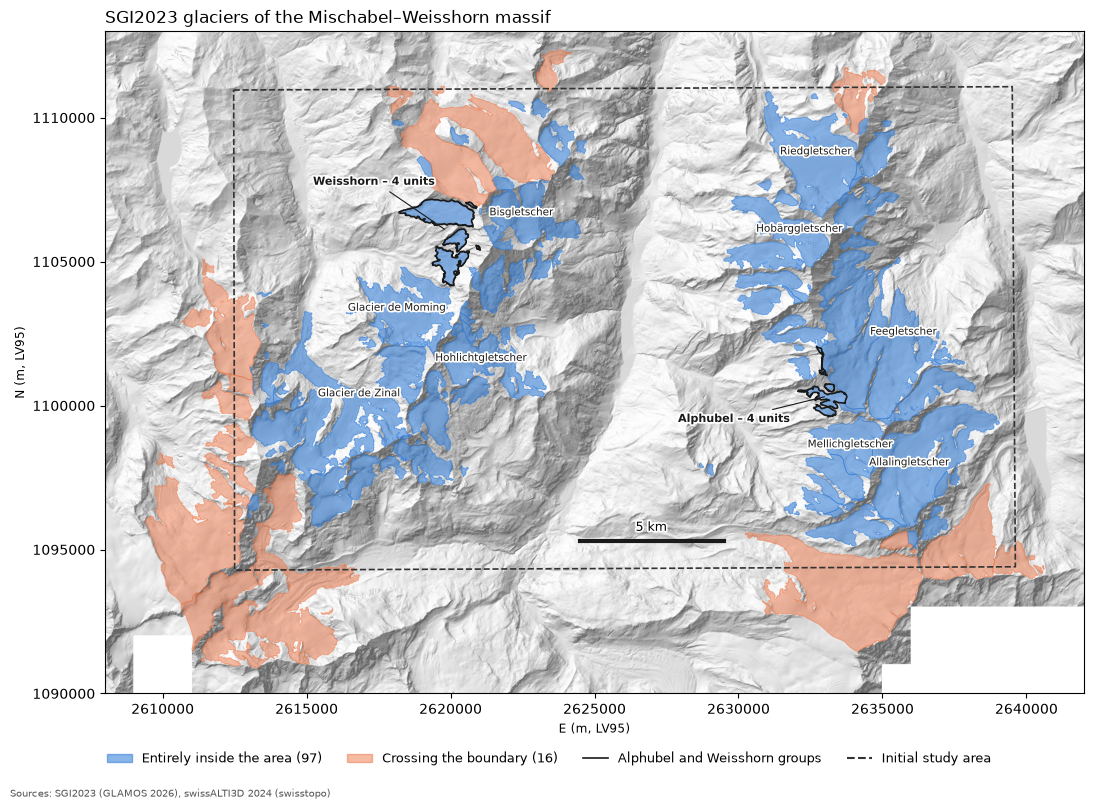

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#1a1a1a"
halo = [pe.withStroke(linewidth=2.5, foreground="white")]
crossing = intersecting[~intersecting.index.isin(inside.index)]

# Simple labels: the large glaciers entirely inside the area
large = inside[inside["area_km2"] > 2.5]

# Key groups for the study: dark outline and a single offset label per group
groups = {
    "Alphubel": ("Alphubel", (-3200, -900)),
    "Weisshorn": ("Weisshorn", (-2500, 1600)),
}

fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(shade, cmap="gray", extent=dem_extent, vmin=-0.2, vmax=1, alpha=0.6)
inside.plot(ax=ax, color=BLUE, alpha=0.55, edgecolor=BLUE, linewidth=0.6)
crossing.plot(ax=ax, color=ORANGE, alpha=0.45, edgecolor=ORANGE, linewidth=0.6)
area.boundary.plot(ax=ax, color="#333333", linewidth=1.2, linestyle="--")

for _, g in large.iterrows():
    p = g.geometry.representative_point()
    ax.annotate(g["name"], (p.x, p.y), fontsize=7.5, ha="center", color=INK, path_effects=halo)

for label, (pattern, (dx, dy)) in groups.items():
    sel = inside[inside["name"].str.contains(pattern)]
    sel.boundary.plot(ax=ax, color=INK, linewidth=1.2)
    c = sel.union_all().centroid
    ax.annotate(f"{label} – {len(sel)} units", (c.x, c.y), xytext=(c.x + dx, c.y + dy),
                fontsize=8, fontweight="bold", ha="center", color=INK, path_effects=halo,
                arrowprops=dict(arrowstyle="-", color=INK, linewidth=0.8))

# 5 km scale bar, in the Zermatt–Saas valley (no glacier there)
x0, y0 = 2624500, 1095300
ax.plot([x0, x0 + 5000], [y0, y0], color=INK, linewidth=3)
ax.text(x0 + 2500, y0 + 350, "5 km", ha="center", fontsize=9, path_effects=halo)

ax.set_xlim(dem_extent[0], dem_extent[1])
ax.set_ylim(dem_extent[2], dem_extent[3])
ax.set_xlabel("E (m, LV95)")
ax.set_ylabel("N (m, LV95)")
ax.ticklabel_format(style="plain")
ax.set_title("SGI2023 glaciers of the Mischabel–Weisshorn massif", loc="left")

# Legend below the map so that no glacier is hidden
fig.legend(handles=[
    Patch(color=BLUE, alpha=0.55, label=f"Entirely inside the area ({len(inside)})"),
    Patch(color=ORANGE, alpha=0.45, label=f"Crossing the boundary ({len(crossing)})"),
    Line2D([], [], color=INK, linewidth=1.2, label="Alphubel and Weisshorn groups"),
    Line2D([], [], color="#333333", linestyle="--", label="Initial study area"),
], loc="lower center", ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0.03))
fig.text(0.01, 0.005, "Sources: SGI2023 (GLAMOS 2026), swissALTI3D 2024 (swisstopo)",
         fontsize=7, color="#555555")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(ROOT / "figures/01_glacier_map.png", dpi=200)
plt.show()